#Load Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
rng = np.random.default_rng(42)
pd.set_option('display.max_columns', 50)
sns.set_style('darkgrid')



#Load Dataset

In [ ]:
os.environ['KAGGLE_USERNAME'] = 'APIKEY'

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("brendan45774/test-file")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'test-file' dataset.
Path to dataset files: /kaggle/input/test-file


In [ ]:
import shutil as st
st.copytree(path,'/content/Dataset',dirs_exist_ok=True)


'/content/Dataset'

In [ ]:
df = pd.read_csv('/content/Dataset/tested.csv')

###Select Numerical and Categorical Columns

In [ ]:
numCol = df.select_dtypes(include=np.number).columns
catCol = df.select_dtypes(exclude=np.number).columns

In [ ]:
print(numCol)
print(catCol)

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


In [ ]:
df[numCol].head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,892,0,3,34.5,0,0,7.8292
1,893,1,3,47.0,1,0,7.0000
2,894,0,2,62.0,0,0,9.6875
3,895,0,3,27.0,0,0,8.6625
4,896,1,3,22.0,1,1,12.2875


In [ ]:
df[numCol].describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


###Mean,Median and Mode

In [ ]:
print("Mean:")
print(df[numCol].mean())
print("-"*50)
print("Median:")
print(df[numCol].median())
print("-"*50)
print("Mode:")
print(df[numCol].mode())

Mean:
PassengerId    1100.500000
Survived          0.363636
Pclass            2.265550
Age              30.272590
SibSp             0.447368
Parch             0.392344
Fare             35.627188
dtype: float64
--------------------------------------------------
Median:
PassengerId    1100.5000
Survived          0.0000
Pclass            3.0000
Age              27.0000
SibSp             0.0000
Parch             0.0000
Fare             14.4542
dtype: float64
--------------------------------------------------
Mode:
     PassengerId  Survived  Pclass   Age  SibSp  Parch  Fare
0            892       0.0     3.0  21.0    0.0    0.0  7.75
1            893       NaN     NaN  24.0    NaN    NaN   NaN
2            894       NaN     NaN   NaN    NaN    NaN   NaN
3            895       NaN     NaN   NaN    NaN    NaN   NaN
4            896       NaN     NaN   NaN    NaN    NaN   NaN
..           ...       ...     ...   ...    ...    ...   ...
413         1305       NaN     NaN   NaN    NaN    NaN   

###Variance And Standard Deviation

In [ ]:
print("Variance")
print(df[numCol].var())
print("-"*50)
print("Standard Deviation")
print(df[numCol].std())

Variance
PassengerId    14595.166667
Survived           0.231960
Pclass             0.708690
Age              201.106695
SibSp              0.804178
Parch              0.963203
Fare            3125.657074
dtype: float64
--------------------------------------------------
Standard Deviation
PassengerId    120.810458
Survived         0.481622
Pclass           0.841838
Age             14.181209
SibSp            0.896760
Parch            0.981429
Fare            55.907576
dtype: float64


###Skewness and Kurtosis

In [ ]:
print("Skewness")
print(df[numCol].skew())
print("-"*50)
print("Kurtosis")
print(df[numCol].kurt())

Skewness
PassengerId    0.000000
Survived       0.568991
Pclass        -0.534170
Age            0.457361
SibSp          4.168337
Parch          4.654462
Fare           3.687213
dtype: float64
--------------------------------------------------
Kurtosis
PassengerId    -1.200000
Survived       -1.684332
Pclass         -1.382666
Age             0.083783
SibSp          26.498712
Parch          31.412513
Fare           17.921595
dtype: float64


###Histogram

In [ ]:
df2 = df[numCol].copy()
df2.drop(columns=['PassengerId','Survived','Pclass'],inplace=True)
print(df2.head())
print('-'*50)
print(df2.describe())

    Age  SibSp  Parch     Fare
0  34.5      0      0   7.8292
1  47.0      1      0   7.0000
2  62.0      0      0   9.6875
3  27.0      0      0   8.6625
4  22.0      1      1  12.2875
--------------------------------------------------
              Age       SibSp       Parch        Fare
count  332.000000  418.000000  418.000000  417.000000
mean    30.272590    0.447368    0.392344   35.627188
std     14.181209    0.896760    0.981429   55.907576
min      0.170000    0.000000    0.000000    0.000000
25%     21.000000    0.000000    0.000000    7.895800
50%     27.000000    0.000000    0.000000   14.454200
75%     39.000000    1.000000    0.000000   31.500000
max     76.000000    8.000000    9.000000  512.329200


Age      0.457361
SibSp    4.168337
Parch    4.654462
Fare     3.687213
dtype: float64
----------------------------------------------------------------------------------------------------
Age       0.083783
SibSp    26.498712
Parch    31.412513
Fare     17.921595
dtype: float64
----------------------------------------------------------------------------------------------------


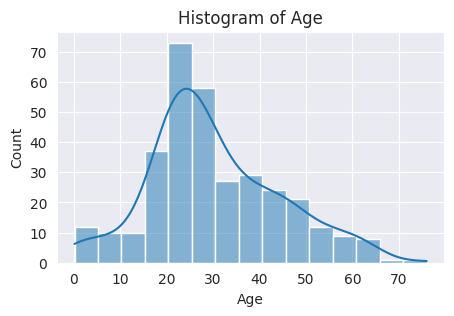

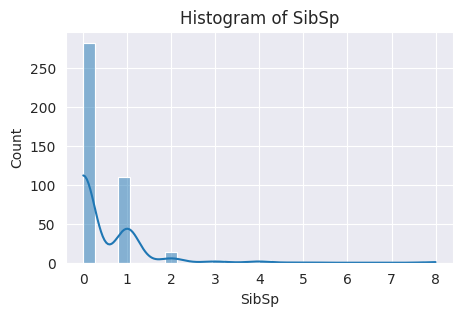

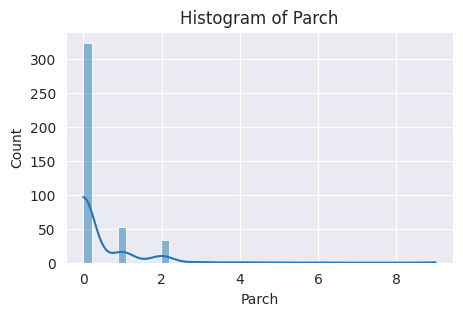

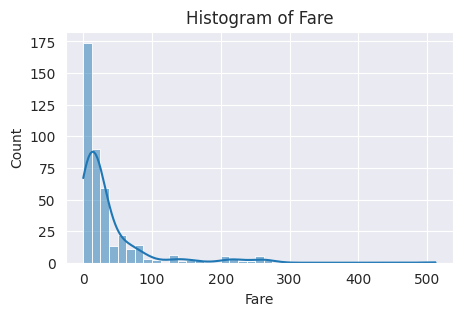

In [ ]:
print(df2.skew())
print('--'*50)
print(df2.kurt())
print('--'*50)
for col in df2.columns:
  plt.figure(figsize=(5,3))
  plt.title(f'Histogram of {col}')
  sns.histplot(df2[col],kde=True)
  plt.show()

#Boxplot

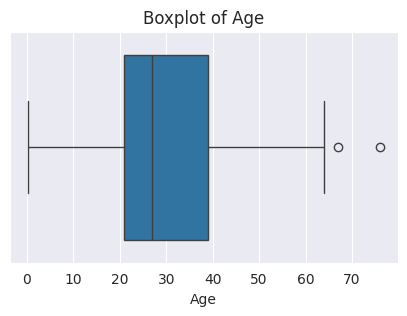

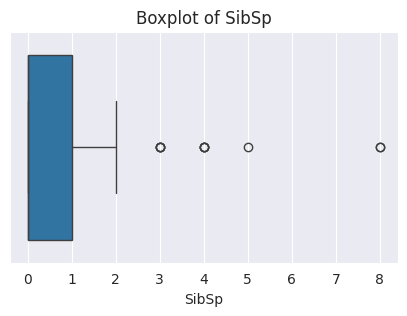

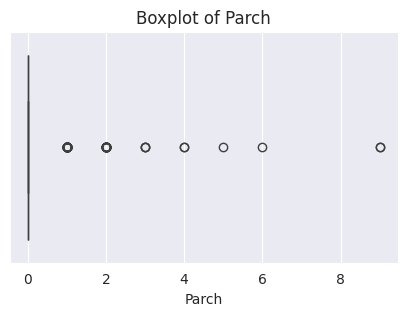

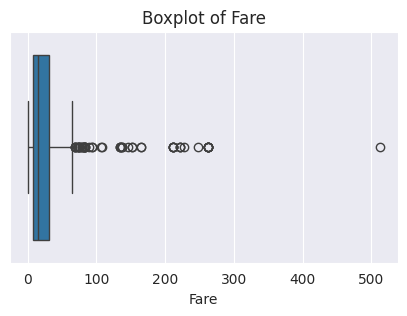

In [ ]:
for col in df2.columns:
  plt.figure(figsize=(5,3))
  plt.title(f'Boxplot of {col}')
  sns.boxplot(x = df2[col])
  plt.show()

###Categorical Features - Analysis

In [ ]:
catCol=catCol.append(pd.Index(['Survived','Pclass']))
df2 = df[catCol].copy()

print(df2.head())

                                           Name     Sex   Ticket Cabin  \
0                              Kelly, Mr. James    male   330911   NaN   
1              Wilkes, Mrs. James (Ellen Needs)  female   363272   NaN   
2                     Myles, Mr. Thomas Francis    male   240276   NaN   
3                              Wirz, Mr. Albert    male   315154   NaN   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  3101298   NaN   

  Embarked  PassengerId  Survived  Pclass  
0        Q          892         0       3  
1        S          893         1       3  
2        Q          894         0       2  
3        S          895         0       3  
4        S          896         1       3  


###Frequency Table

In [ ]:
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [ ]:
catCol = df.select_dtypes(include=['object']).columns.to_list()
catCol += ['Survived', 'Pclass',]
catCol = [x for x in catCol if x not in ['Name','Ticket','Cabin']]
print(catCol)

['Sex', 'Embarked', 'Survived', 'Pclass']


In [ ]:
for col in catCol:
  print(f"Frequency Table for {col}")
  print(df[col].value_counts())
  print('normalize'*50)
  print(df[col].value_counts(normalize=True))
  print('-'*50)




Frequency Table for Sex
Sex
male      266
female    152
Name: count, dtype: int64
normalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalize
Sex
male      0.636364
female    0.363636
Name: proportion, dtype: float64
--------------------------------------------------
Frequency Table for Embarked
Embarked
S    270
C    102
Q     46
Name: count, dtype: int64
normalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormalizenormali

###countplot

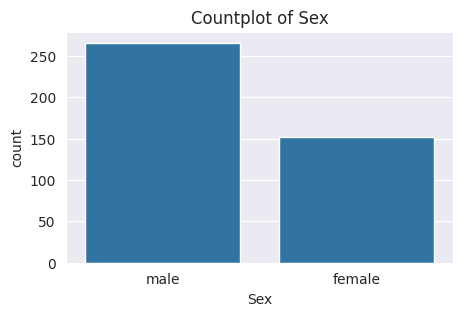

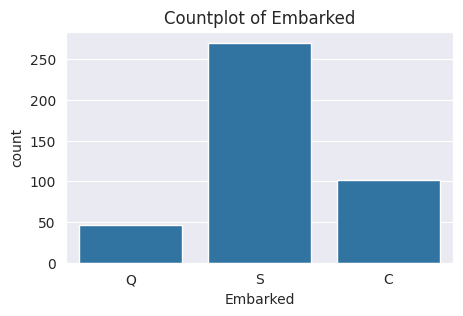

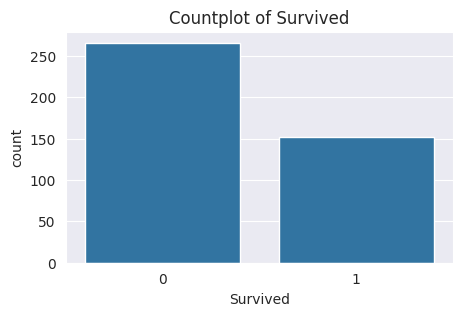

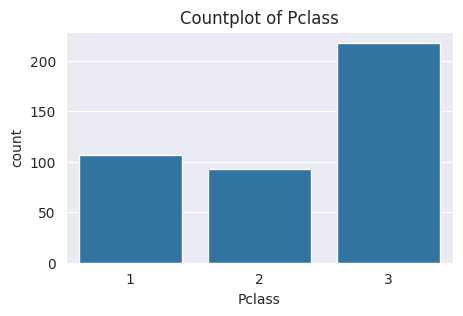

In [ ]:
for col in catCol:
  plt.figure(figsize=(5,3))
  plt.title(f'Countplot of {col}')
  sns.countplot(x = df[col])
  plt.show()